In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import math as mt

In [2]:
psi_x = np.linspace(0,10,1000)
a = psi_x[1]
H = np.zeros((len(psi_x),len(psi_x)))
H[0,0],H[0,1] = 1/a**2, -1/(2*a**2)
H[999,999],H[999,998] =  1/a**2, -1/(2*a**2)

count_j = 1
for i in range(1,999):
    H[i,count_j-1], H[i,count_j],H[i,count_j+1] = -1/(2*a**2), 1/a**2, -1/(2*a**2)
    count_j = count_j+1


In [3]:
lambda_e, lamda_f = np.linalg.eigh(H)

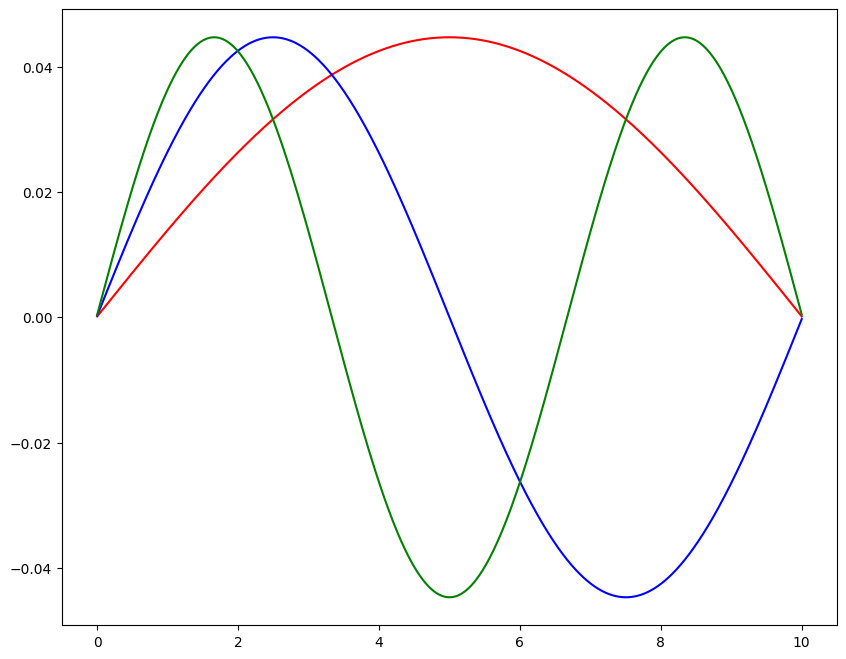

In [4]:
plt.figure(figsize=(10,8))
plt.plot(psi_x,-lamda_f[:,0],'r')
plt.plot(psi_x,-lamda_f[:,1],'b')
plt.plot(psi_x,-lamda_f[:,2],'g')

plt.show()


## Harmonic Oscillator


In [5]:
psi_x = np.linspace(-3,3,1000)
a = psi_x[1]-psi_x[0]
H = np.zeros((len(psi_x),len(psi_x)))
H[0,0],H[0,1] = 1/a**2+ psi_x[0]**2, -1/(2*a**2) 
H[999,999],H[999,998] =  1/a**2+ psi_x[999]**2, -1/(2*a**2)

count_j = 1
for i in range(1,999):
    H[i,count_j-1], H[i,count_j],H[i,count_j+1] = -1/(2*a**2), 1/a**2 + psi_x[i]**2, -1/(2*a**2)
    count_j = count_j+1


In [6]:
lamdaSHO_e, lamdaSHO_f = np.linalg.eigh(H)


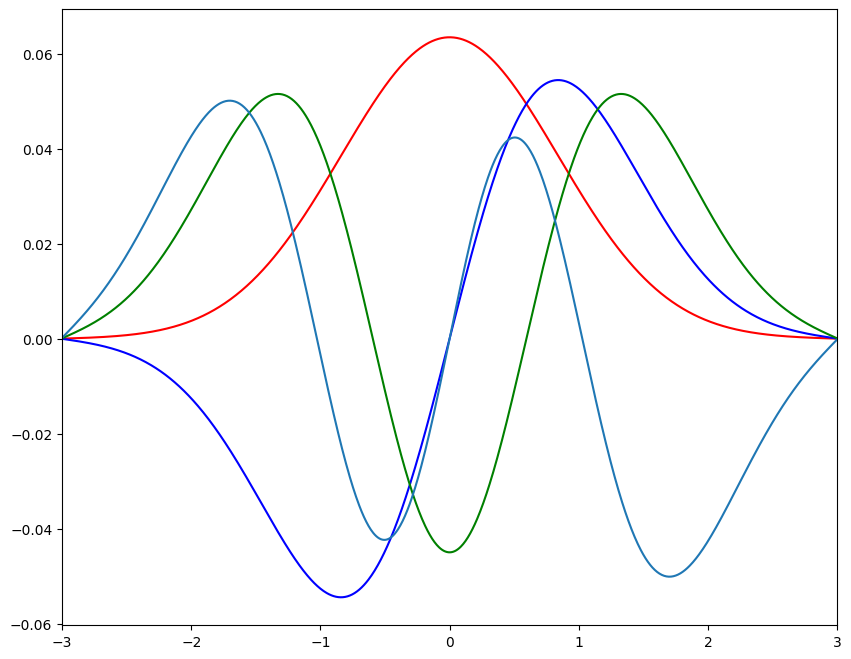

In [7]:
plt.figure(figsize=(10,8))
plt.plot(psi_x,lamdaSHO_f[:,0],'r')
plt.plot(psi_x,lamdaSHO_f[:,1],'b')
plt.plot(psi_x,lamdaSHO_f[:,2],'g')
plt.plot(psi_x,lamdaSHO_f[:,3])

plt.xlim(-3,3)

plt.show()


## Density

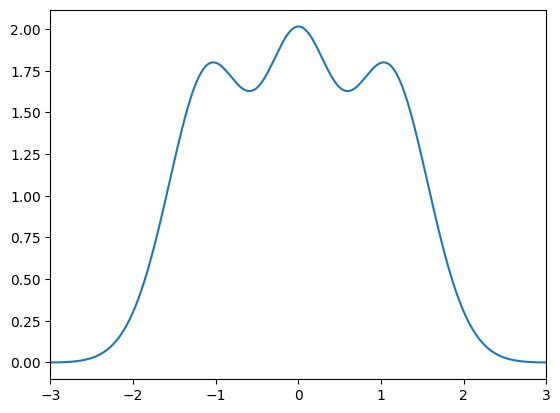

In [8]:
occupation = 2
n_x = (occupation/a)*((abs(lamdaSHO_f[:,0]))**2+(abs(lamdaSHO_f[:,1]))**2+(abs(lamdaSHO_f[:,2]))**2)
plt.plot(psi_x,n_x)
plt.xlim(-3,3)
plt.show()


## Exchange Pontetial and Energy

In [9]:
def calculate_exchange(dx,density):
    Ex_potential = -(3/mt.pi)*density**(1/3)
    sum = 0
    for i in range(len(density)):
        sum = sum + dx*(density[i])**4/3
    Ex_Energy = sum*(-3/4)*(3/mt.pi)
    return Ex_potential,Ex_Energy

        


-6.700731518629586


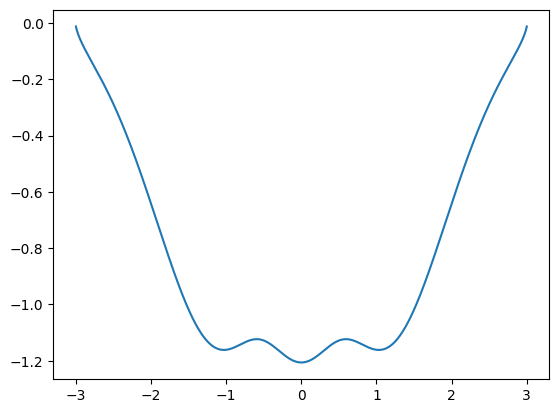

In [10]:
Ex_Potential,Ex_Energy = calculate_exchange(a,n_x)
print(Ex_Energy)
plt.plot(psi_x,Ex_Potential)
plt.show()

## Coloumb Potential and energy

In [11]:
def Calculate_ColoumbE(dx, density):
    
    x_c = np.linspace(-3,3,1000)
    dx,dx_p = x_c[1]-x_c[0],x_c[1]-x_c[0]
    nxsum = 0
    for nx,x in zip(density,x_c):
        npsum = 0
        for nx_p,xp in zip(density,x_c):
            npsum = npsum + (nx*nx_p/np.sqrt((x-xp)**2+1))*dx_p
        nxsum = nxsum+ npsum*dx
    ColumbE = 0.5*nxsum
    Coloumb_P = []
    for x in x_c:
        npsum = 0
        for nx_p,xp in zip(density,x_c):
            npsum = npsum + (nx_p/np.sqrt((x-xp)**2+1))*dx_p
        Coloumb_P.append(npsum)
    return Coloumb_P,ColumbE

        


In [12]:
ColoumbP, ColoumbE = Calculate_ColoumbE(a,n_x)

In [13]:
len(ColoumbP)

1000

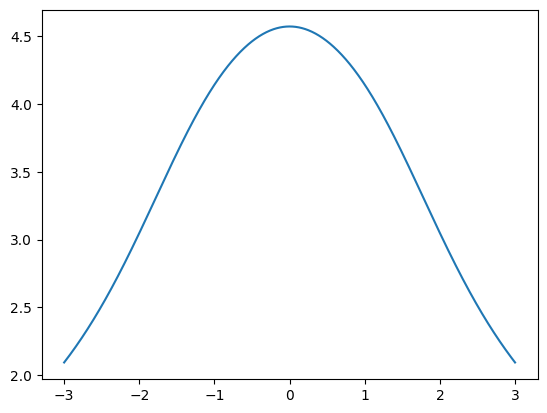

In [14]:
plt.plot(psi_x,ColoumbP)
plt.show()

## Self Consistency Loop